# PathSnap — Person B Complete ML Workflow

Run these cells from top to bottom. This notebook:
1. Uploads and extracts your ZIP / Parquet files.
2. Detects the `Label` column (capital L).
3. Builds a trip-grouped sample for practical model comparison.
4. Compares Logistic Regression, KNN, Random Forest, XGBoost and MLP using 5-fold GroupKFold.
5. Tunes Random Forest with Optuna using the same trip-grouped sample.
6. Fits the selected model on the full labelled training dataset and exports the model, metadata and metrics.

**Important:** The supplied training data has 1,944,875 rows, 80 trips and binary labels (`0`, `1`). The sample comparison/tuning is a practical model-selection stage. Final fitting uses the full labelled training dataset. Do not use the student test dataset for training or tuning.

## 1. Install required packages

In [1]:
%pip -q install numpy pandas scikit-learn pyarrow xgboost optuna joblib

## 2. Upload your updated project ZIP (or labelled Parquet)

In [2]:
from google.colab import files
uploaded_files = files.upload()
print("Uploaded files:", list(uploaded_files.keys()))

Saving labelled_training_data.parquet to labelled_training_data.parquet
Saving PathSnap_PersonB_Complete.zip to PathSnap_PersonB_Complete.zip
Uploaded files: ['labelled_training_data.parquet', 'PathSnap_PersonB_Complete.zip']


## 3. Extract files and locate the labelled Parquet

In [3]:
import os, zipfile, shutil, glob, warnings, json, time
from pathlib import Path

WORK = Path("/content/PathSnap_PersonB_Run")
WORK.mkdir(parents=True, exist_ok=True)

for filename, content in uploaded_files.items():
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename) as zf:
            zf.extractall(WORK)
    elif filename.lower().endswith((".parquet", ".pq")):
        (WORK / filename).write_bytes(content)

parquet_files = list(WORK.rglob("*.parquet")) + list(WORK.rglob("*.pq"))
print("Parquet files found:")
for p in parquet_files:
    print(" -", p)

labelled = [p for p in parquet_files
            if "label" in p.name.lower() and "test" not in p.name.lower()]
if labelled:
    TRAIN_PARQUET = labelled[0]
else:
    # Fall back to a Parquet containing the required target column.
    import pandas as pd
    TRAIN_PARQUET = None
    for p in parquet_files:
        cols = pd.read_parquet(p).columns
        if "Label" in cols or "label" in cols:
            TRAIN_PARQUET = p
            break

if TRAIN_PARQUET is None:
    raise FileNotFoundError(
        "No labelled Parquet found. Upload the ZIP containing labelled_training_data.parquet "
        "or upload that Parquet separately."
    )

print("\nSelected labelled training file:", TRAIN_PARQUET)

Parquet files found:
 - /content/PathSnap_PersonB_Run/labelled_training_data.parquet

Selected labelled training file: /content/PathSnap_PersonB_Run/labelled_training_data.parquet


## 4. Inspect labels and validate the data

In [4]:
import pandas as pd
import numpy as np

df = pd.read_parquet(TRAIN_PARQUET)
LABEL_COLUMN = "Label" if "Label" in df.columns else (
    "label" if "label" in df.columns else None
)

if LABEL_COLUMN is None:
    raise ValueError(f"No Label/label column found. Columns: {df.columns.tolist()}")
if "Trip_ID" not in df.columns:
    raise ValueError("Trip_ID is required for trip-grouped cross-validation.")

df = df.dropna(subset=[LABEL_COLUMN, "Trip_ID"]).copy()
print("Shape:", df.shape)
print("Label column:", LABEL_COLUMN)
print("Trips:", df["Trip_ID"].nunique())
print("\nLabel distribution:")
display(df[LABEL_COLUMN].value_counts(dropna=False).to_frame("rows"))
print("\nClass proportions:")
display(df[LABEL_COLUMN].value_counts(normalize=True).to_frame("proportion"))

if df[LABEL_COLUMN].nunique() < 2:
    raise ValueError("The target must contain at least two classes.")

Shape: (1944875, 15)
Label column: Label
Trips: 80

Label distribution:


,rows
Label,
0,1756912
1,187963



Class proportions:


,proportion
Label,
0,0.903355
1,0.096645


## 5. Create a practical trip-grouped sample

In [5]:
# The current labelled data has ~1.94M rows. Comparing every model on all rows
# across five folds is unnecessarily slow. Sample up to 300 rows per trip.
SAMPLE_ROWS_PER_TRIP = 300
sample_df = (
    df.groupby("Trip_ID", group_keys=False)
      .apply(lambda g: g.sample(
          n=min(len(g), SAMPLE_ROWS_PER_TRIP), random_state=42
      ))
      .reset_index(drop=True)
)

print("Full labelled rows:", f"{len(df):,}")
print("Sample rows:", f"{len(sample_df):,}")
print("Trips in sample:", sample_df["Trip_ID"].nunique())
print("Sample label counts:")
display(sample_df[LABEL_COLUMN].value_counts().to_frame("rows"))

Full labelled rows: 1,944,875
Sample rows: 24,000
Trips in sample: 80
Sample label counts:


/tmp/ipykernel_767/3186600925.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(


,rows
Label,
0,21432
1,2568


## 6. Define features, preprocessing and model builders

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

NUMERIC_FEATURES = [
    "distance_m", "search_radius_m", "gps_speed_mps", "segment_length_m",
    "heading_difference_deg", "gps_heading_sin", "gps_heading_cos",
    "segment_heading_sin", "segment_heading_cos"
]
CATEGORICAL_FEATURES = ["speed_quality"]

def engineer_features(frame):
    z = frame.copy()
    for c in ["gps_heading_deg", "segment_heading_deg"]:
        if c not in z.columns:
            z[c] = np.nan
    gps = np.deg2rad(pd.to_numeric(z["gps_heading_deg"], errors="coerce"))
    seg = np.deg2rad(pd.to_numeric(z["segment_heading_deg"], errors="coerce"))
    z["gps_heading_sin"], z["gps_heading_cos"] = np.sin(gps), np.cos(gps)
    z["segment_heading_sin"], z["segment_heading_cos"] = np.sin(seg), np.cos(seg)
    for c in NUMERIC_FEATURES:
        if c not in z.columns:
            z[c] = np.nan
    if "speed_quality" not in z.columns:
        z["speed_quality"] = "missing"
    z["speed_quality"] = z["speed_quality"].fillna("missing").astype(str)
    return z[NUMERIC_FEATURES + CATEGORICAL_FEATURES]

def build_preprocessor():
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", num_pipe, NUMERIC_FEATURES),
        ("categorical", cat_pipe, CATEGORICAL_FEATURES)
    ])

# Labels verified from the uploaded dataset are 0 and 1.
def build_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1500, class_weight="balanced", random_state=42
        ),
        "KNN": KNeighborsClassifier(
            n_neighbors=5, weights="distance", n_jobs=-1
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, class_weight="balanced",
            random_state=42, n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=100, max_depth=5, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            objective="binary:logistic", eval_metric="logloss",
            random_state=42, n_jobs=-1
        ),
        "MLP": MLPClassifier(
            hidden_layer_sizes=(64, 32), max_iter=150,
            early_stopping=True, random_state=42
        )
    }

X_sample = engineer_features(sample_df)
y_sample = sample_df[LABEL_COLUMN].astype(int)
groups_sample = sample_df["Trip_ID"].astype(str)

print("Feature matrix:", X_sample.shape)
print("Classes:", sorted(y_sample.unique().tolist()))

Feature matrix: (24000, 10)
Classes: [0, 1]


## 7. Compare all five models with 5-fold GroupKFold

In [7]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import clone

N_FOLDS = min(5, groups_sample.nunique())
cv = GroupKFold(n_splits=N_FOLDS)
comparison_rows = []

for model_name, estimator in build_models().items():
    print(f"\n===== {model_name} =====", flush=True)
    for fold, (tr_idx, va_idx) in enumerate(
        cv.split(X_sample, y_sample, groups_sample), start=1
    ):
        pipe = Pipeline([
            ("preprocessor", build_preprocessor()),
            ("classifier", clone(estimator))
        ])
        t0 = time.time()
        pipe.fit(X_sample.iloc[tr_idx], y_sample.iloc[tr_idx])
        pred = pipe.predict(X_sample.iloc[va_idx])
        elapsed = time.time() - t0

        row = {
            "model": model_name,
            "fold": fold,
            "accuracy": accuracy_score(y_sample.iloc[va_idx], pred),
            "precision_macro": precision_score(
                y_sample.iloc[va_idx], pred, average="macro", zero_division=0
            ),
            "recall_macro": recall_score(
                y_sample.iloc[va_idx], pred, average="macro", zero_division=0
            ),
            "macro_f1": f1_score(
                y_sample.iloc[va_idx], pred, average="macro", zero_division=0
            ),
            "train_and_predict_seconds": elapsed
        }
        comparison_rows.append(row)
        print(
            f"Fold {fold}/{N_FOLDS} | macro-F1={row['macro_f1']:.4f} "
            f"| accuracy={row['accuracy']:.4f} | {elapsed:.1f}s",
            flush=True
        )

fold_results = pd.DataFrame(comparison_rows)
summary = (
    fold_results.groupby("model")
    .agg(
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        precision_macro_mean=("precision_macro", "mean"),
        recall_macro_mean=("recall_macro", "mean"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        mean_seconds=("train_and_predict_seconds", "mean")
    )
    .sort_values("macro_f1_mean", ascending=False)
)

display(summary)


===== Logistic Regression =====
Fold 1/5 | macro-F1=0.7385 | accuracy=0.8390 | 0.3s
Fold 2/5 | macro-F1=0.7041 | accuracy=0.8285 | 0.3s
Fold 3/5 | macro-F1=0.7294 | accuracy=0.8602 | 0.2s
Fold 4/5 | macro-F1=0.7129 | accuracy=0.8313 | 0.3s
Fold 5/5 | macro-F1=0.7431 | accuracy=0.8548 | 0.2s

===== KNN =====
Fold 1/5 | macro-F1=0.8174 | accuracy=0.9271 | 1.1s
Fold 2/5 | macro-F1=0.7630 | accuracy=0.9163 | 1.2s
Fold 3/5 | macro-F1=0.7668 | accuracy=0.9287 | 1.2s
Fold 4/5 | macro-F1=0.7547 | accuracy=0.9169 | 1.4s
Fold 5/5 | macro-F1=0.7956 | accuracy=0.9271 | 1.8s

===== Random Forest =====
Fold 1/5 | macro-F1=0.8408 | accuracy=0.9402 | 7.1s
Fold 2/5 | macro-F1=0.7829 | accuracy=0.9269 | 4.0s
Fold 3/5 | macro-F1=0.8042 | accuracy=0.9421 | 5.7s
Fold 4/5 | macro-F1=0.7476 | accuracy=0.9210 | 4.0s
Fold 5/5 | macro-F1=0.8143 | accuracy=0.9363 | 4.1s

===== XGBoost =====
Fold 1/5 | macro-F1=0.8500 | accuracy=0.9413 | 0.5s
Fold 2/5 | macro-F1=0.8000 | accuracy=0.9302 | 0.3s
Fold 3/5 | macro-F

,accuracy_mean,accuracy_std,precision_macro_mean,recall_macro_mean,macro_f1_mean,macro_f1_std,mean_seconds
model,,,,,,,
XGBoost,0.936833,0.007150,0.853043,0.792183,0.818296,0.025881,0.826518
MLP,0.934667,0.005220,0.844011,0.792712,0.814362,0.022842,2.322968
Random Forest,0.933292,0.009016,0.854686,0.761385,0.797948,0.035013,4.987005
KNN,0.923208,0.006109,0.809313,0.757322,0.779486,0.026206,1.333883
Logistic Regression,0.842750,0.014127,0.689760,0.861210,0.725600,0.016679,0.271748


## 8. Optuna tuning — Random Forest

In [12]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def rf_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 80, 220, step=20),
        "max_depth": trial.suggest_int("max_depth", 4, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 15),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "class_weight": "balanced",
        "random_state": 42,
        "n_jobs": -1
    }
    scores = []
    for tr_idx, va_idx in cv.split(X_sample, y_sample, groups_sample):
        pipe = Pipeline([
            ("preprocessor", build_preprocessor()),
            ("classifier", RandomForestClassifier(**params))
        ])
        pipe.fit(X_sample.iloc[tr_idx], y_sample.iloc[tr_idx])
        pred = pipe.predict(X_sample.iloc[va_idx])
        scores.append(f1_score(
            y_sample.iloc[va_idx], pred,
            average="macro", zero_division=0
        ))
    return float(np.mean(scores))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(rf_objective, n_trials=10, show_progress_bar=True)

print("Best Optuna macro-F1:", study.best_value)
print("Best parameters:", study.best_params)

  0%|          | 0/10 [00:00<?, ?it/s]

Best Optuna macro-F1: 0.8222974998443473
Best parameters: {'n_estimators': 140, 'max_depth': 17, 'min_samples_split': 4, 'min_samples_leaf': 5}


In [13]:
pos_weight = float((y_sample == 0).sum() / (y_sample == 1).sum())

def xgb_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 10, log=True),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1, pos_weight),
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "random_state": 42,
        "n_jobs": -1,
    }
    scores = []
    for tr_idx, va_idx in cv.split(X_sample, y_sample, groups_sample):
        pipe = Pipeline([
            ("preprocessor", build_preprocessor()),
            ("classifier", XGBClassifier(**params))
        ])
        pipe.fit(X_sample.iloc[tr_idx], y_sample.iloc[tr_idx])
        pred = pipe.predict(X_sample.iloc[va_idx])
        scores.append(f1_score(y_sample.iloc[va_idx], pred, average="macro", zero_division=0))
    return float(np.mean(scores))

xgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
xgb_study.optimize(xgb_objective, n_trials=10, show_progress_bar=True)

print("Best XGBoost macro-F1:", xgb_study.best_value)
print("Best parameters:", xgb_study.best_params)

  0%|          | 0/10 [00:00<?, ?it/s]

Best XGBoost macro-F1: 0.8271579179616599
Best parameters: {'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.016149614799999188, 'subsample': 0.9208787923016158, 'colsample_bytree': 0.6298202574719083, 'min_child_weight': 10, 'reg_lambda': 2.0736445177905036, 'scale_pos_weight': 2.4597245391201823}


## 9. Select the model and fit the final model on the full labelled dataset

In [14]:
# Fair comparison: both tuned models vs. the best untuned baseline, same folds.
candidates = {
    "Tuned Random Forest": study.best_value,
    "Tuned XGBoost": xgb_study.best_value,
    summary.index[0] + " (baseline)": float(summary.iloc[0]["macro_f1_mean"]),
}
for k, v in candidates.items():
    print(f"{k}: {v:.4f}")

selected_name = max(candidates, key=candidates.get)

if selected_name == "Tuned Random Forest":
    final_estimator = RandomForestClassifier(
        **study.best_params, class_weight="balanced", random_state=42, n_jobs=-1
    )
elif selected_name == "Tuned XGBoost":
    final_estimator = XGBClassifier(
        **xgb_study.best_params, objective="binary:logistic",
        eval_metric="logloss", random_state=42, n_jobs=-1
    )
else:
    selected_name = summary.index[0]
    final_estimator = build_models()[selected_name]

print("Selected model:", selected_name)

X_full = engineer_features(df)
y_full = df[LABEL_COLUMN].astype(int)

final_model = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", final_estimator)
])

print(f"Fitting {selected_name} on {len(df):,} labelled rows...", flush=True)
t0 = time.time()
final_model.fit(X_full, y_full)
full_fit_seconds = time.time() - t0
print(f"Full-data fit completed in {full_fit_seconds/60:.1f} minutes.")

Tuned Random Forest: 0.8223
Tuned XGBoost: 0.8272
XGBoost (baseline): 0.8183
Selected model: Tuned XGBoost
Fitting Tuned XGBoost on 1,944,875 labelled rows...
Full-data fit completed in 0.9 minutes.


## 10. Save model, metadata, metrics and tuning results

In [15]:
import joblib, json
OUT = WORK / "person_b_outputs"
(OUT / "saved_models").mkdir(parents=True, exist_ok=True)
(OUT / "results").mkdir(parents=True, exist_ok=True)

joblib.dump(final_model, OUT / "saved_models" / "best_candidate_classifier.joblib")
fold_results.to_csv(OUT / "results" / "model_comparison_folds.csv", index=False)
summary.to_csv(OUT / "results" / "model_comparison_summary.csv")

with open(OUT / "results" / "optuna_best_params.json", "w") as f:
    json.dump({
        "random_forest": {
            "best_sampled_groupkfold_macro_f1": study.best_value,
            "best_parameters": study.best_params,
            "trials": len(study.trials)
        },
        "xgboost": {
            "best_sampled_groupkfold_macro_f1": xgb_study.best_value,
            "best_parameters": xgb_study.best_params,
            "trials": len(xgb_study.trials)
        }
    }, f, indent=2)

metadata = {
    "selected_model": selected_name,
    "label_column": LABEL_COLUMN,
    "classes": [int(v) for v in final_model.classes_],
    "full_training_rows": int(len(df)),
    "unique_trips": int(df["Trip_ID"].nunique()),
    "sample_rows_for_model_comparison_and_tuning": int(len(sample_df)),
    "validation": f"GroupKFold with {N_FOLDS} folds grouped by Trip_ID",
    "full_fit_seconds": float(full_fit_seconds),
    "features": NUMERIC_FEATURES + CATEGORICAL_FEATURES,
    "warning": "Reported CV metrics are from the sampled dataset, not an independent test set."
}
with open(OUT / "saved_models" / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model and outputs to:", OUT)
print("Selected model:", selected_name)

Saved model and outputs to: /content/PathSnap_PersonB_Run/person_b_outputs
Selected model: Tuned XGBoost


## 11. Download the complete Person B results

In [16]:
import shutil
from google.colab import files

zip_base = "/content/PathSnap_PersonB_Final_Results"
zip_path = shutil.make_archive(zip_base, "zip", root_dir=str(OUT))
print("Created:", zip_path)
files.download(zip_path)

Created: /content/PathSnap_PersonB_Final_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import sklearn, xgboost, pandas, numpy
print(sklearn.__version__, xgboost.__version__, pandas.__version__, numpy.__version__)

1.6.1 3.4.1 2.2.3 2.4.6


In [18]:
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from sklearn.metrics import f1_score

X_full = engineer_features(df)
y_full = df[LABEL_COLUMN].astype(int)
groups_full = df["Trip_ID"].astype(str)

oof = np.zeros(len(df))
fold_id = np.zeros(len(df), dtype=int)
for fold, (tr, va) in enumerate(GroupKFold(n_splits=5).split(X_full, y_full, groups_full), 1):
    pipe = Pipeline([("preprocessor", build_preprocessor()),
                     ("classifier", clone(final_estimator))])
    pipe.fit(X_full.iloc[tr], y_full.iloc[tr])
    oof[va] = pipe.predict_proba(X_full.iloc[va])[:, 1]
    fold_id[va] = fold
    print(f"Fold {fold} done", flush=True)

oof_df = pd.DataFrame({
    "row_id": df.index, "Trip_ID": df["Trip_ID"].values,
    "Label": y_full.values, "prob": oof.round(5), "fold": fold_id
})
oof_path = OUT / "results" / "oof_predictions.parquet"
oof_df.to_parquet(oof_path, index=False)
print("OOF macro-F1 @0.5:", f1_score(y_full, (oof >= 0.5).astype(int), average="macro"))

from google.colab import files
files.download(str(oof_path))

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done
OOF macro-F1 @0.5: 0.8027119681957704


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
print(len(df), study.best_value, xgb_study.best_value)


1944875 0.8222974998443473 0.8271579179616599


In [20]:
(OUT / "results").mkdir(parents=True, exist_ok=True)
study.trials_dataframe().to_csv(OUT/"results"/"optuna_trials_random_forest.csv", index=False)
xgb_study.trials_dataframe().to_csv(OUT/"results"/"optuna_trials_xgboost.csv", index=False)
print("trial logs saved")

trial logs saved


In [22]:
from google.colab import files
up = files.upload()

Saving labelled_training_data.parquet to labelled_training_data (1).parquet


In [23]:
test_path = [k for k in up if k.lower().endswith((".parquet", ".pq"))][0]
test_df = pd.read_parquet(test_path)
test_df = test_df.dropna(subset=[LABEL_COLUMN, "Trip_ID"]).copy()
test_df["Trip_ID"] = test_df["Trip_ID"].astype(str)

RAW_NEEDED = ["distance_m","search_radius_m","gps_speed_mps","segment_length_m",
              "heading_difference_deg","gps_heading_deg","segment_heading_deg","speed_quality"]

print("Shape:", test_df.shape, "| trips:", test_df["Trip_ID"].nunique())
print("Trip overlap with training (must be 0):",
      len(set(test_df["Trip_ID"]) & set(df["Trip_ID"].astype(str))))
print("Missing raw columns:", [c for c in RAW_NEEDED if c not in test_df.columns])
print("Possible observation-ID columns:",
      [c for c in test_df.columns if c not in RAW_NEEDED + [LABEL_COLUMN, "Trip_ID"]])

Shape: (1944875, 15) | trips: 80
Trip overlap with training (must be 0): 80
Missing raw columns: []
Possible observation-ID columns: ['gps_index', 'timestamp', 'arc_id', 'Partition', 'reference_arc_id']


Logistic Regression: macro-F1=0.7156 logloss=0.3235 top1=nan
KNN: macro-F1=0.7763 logloss=0.7702 top1=nan
Random Forest: macro-F1=0.7920 logloss=0.1828 top1=nan
XGBoost: macro-F1=0.8038 logloss=0.1533 top1=nan
MLP: macro-F1=0.8022 logloss=0.1568 top1=nan
Tuned Random Forest: macro-F1=0.8110 logloss=0.1869 top1=nan
Tuned XGBoost: macro-F1=0.8159 logloss=0.1795 top1=nan
Final: Tuned XGBoost (full train data): macro-F1=0.8322 logloss=0.1673 top1=nan


,model,family,cv_macro_f1,train_macro_f1_insample,test_accuracy,test_precision_macro,test_recall_macro,test_macro_f1,test_precision_pos,test_recall_pos,test_f1_pos,test_log_loss,test_roc_auc,top1_all_obs,top1_obs_with_reference,candidate_miss_rate,fit_seconds,inference_ms_per_1000_rows
0,Logistic Regression,Linear / probabilistic,0.7256,0.7293,0.8456,0.6787,0.8593,0.7156,0.3729,0.8763,0.5232,0.3235,0.9310,NaN,NaN,NaN,0.1951,0.9936
1,KNN,Instance-based,0.7795,1.0000,0.9291,0.8091,0.7513,0.7763,0.6674,0.5309,0.5914,0.7702,0.8793,NaN,NaN,NaN,0.0721,136.1056
2,Random Forest,Ensemble (bagging),0.7979,1.0000,0.9369,0.8480,0.7546,0.7920,0.7449,0.5285,0.6183,0.1828,0.9475,NaN,NaN,NaN,6.7905,6.1125
3,XGBoost,Boosting,0.8183,0.8423,0.9382,0.8425,0.7748,0.8038,0.7296,0.5723,0.6414,0.1533,0.9496,NaN,NaN,NaN,0.3842,2.2694
4,MLP,Neural network,0.8144,0.8247,0.9378,0.8414,0.7729,0.8022,0.7280,0.5685,0.6384,0.1568,0.9460,NaN,NaN,NaN,4.4983,1.3908
5,Tuned Random Forest,Ensemble (bagging),0.8223,0.9045,0.9267,0.7844,0.8462,0.8110,0.5966,0.7465,0.6632,0.1869,0.9502,NaN,NaN,NaN,10.3457,8.0093
6,Tuned XGBoost,Boosting,0.8272,0.8637,0.9345,0.8101,0.8219,0.8159,0.6543,0.6825,0.6681,0.1795,0.9480,NaN,NaN,NaN,2.7155,5.2038
7,Final: Tuned XGBoost (full train data),Boosting,0.8272,NaN,0.9386,0.8180,0.8483,0.8322,0.6646,0.7364,0.6987,0.1673,0.9612,NaN,NaN,NaN,54.8192,5.6079


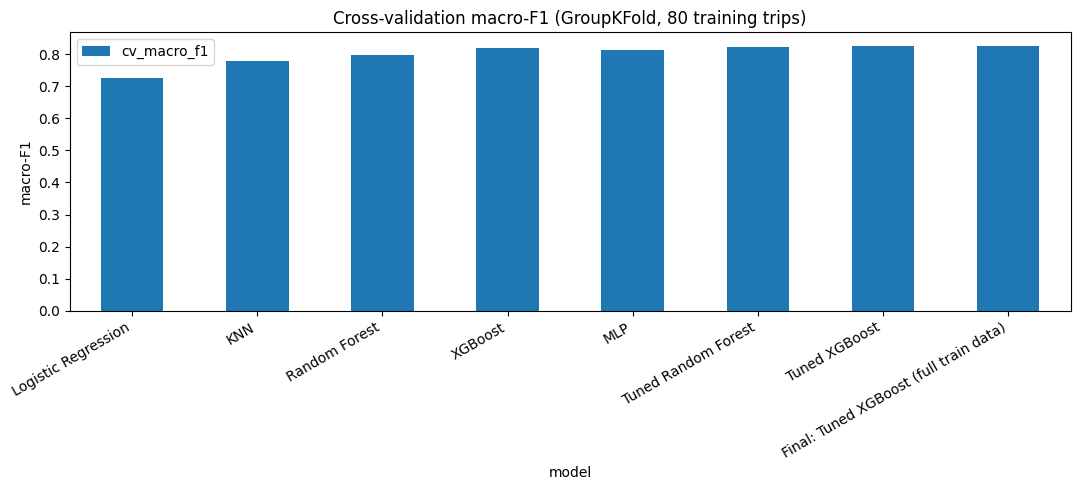

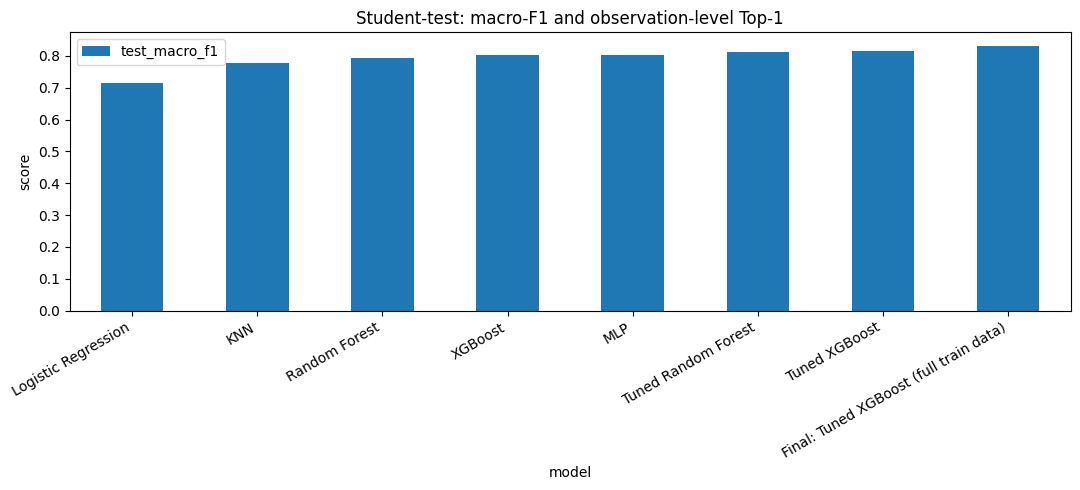

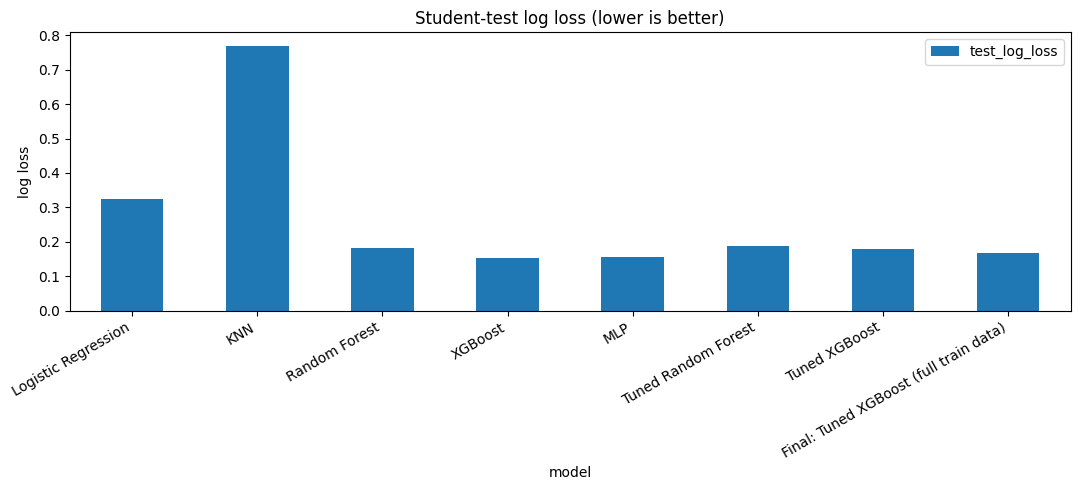

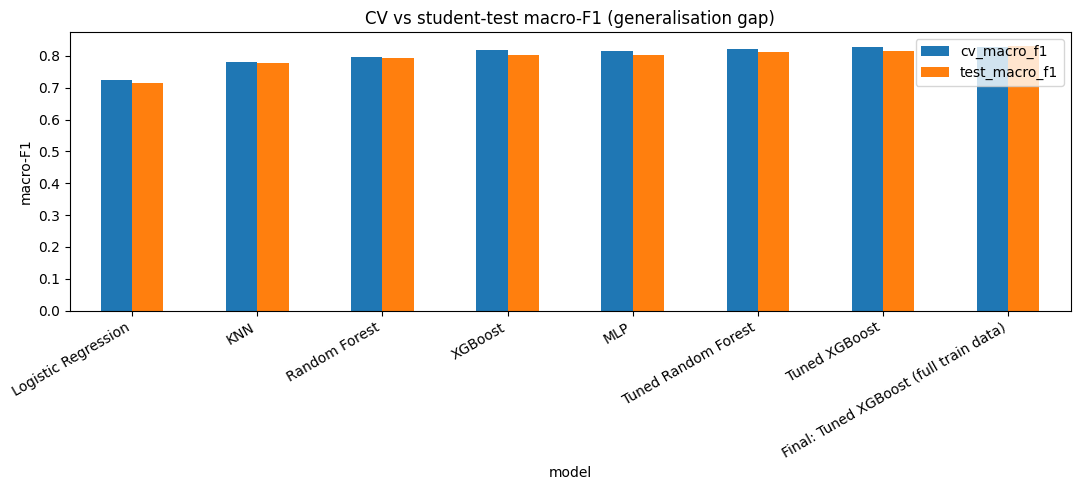

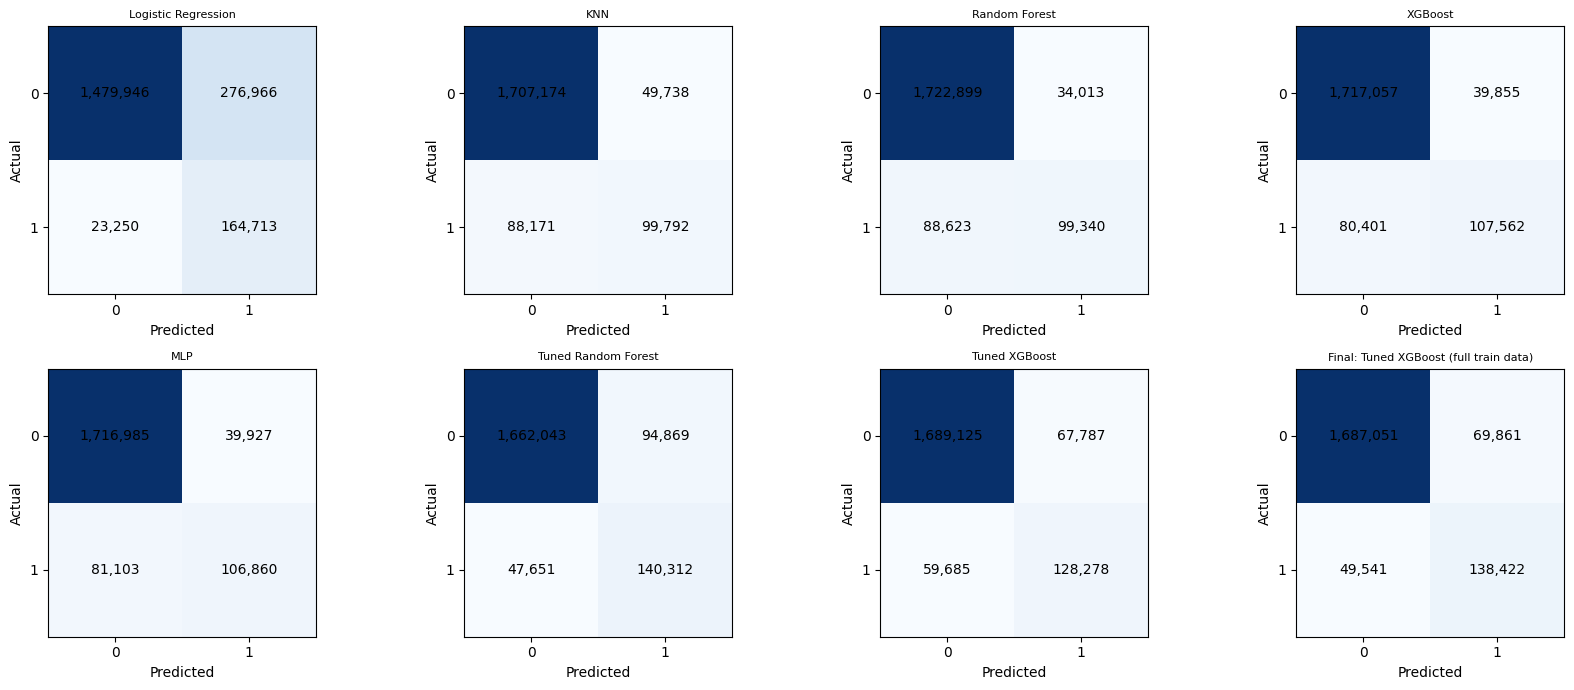

In [24]:
OBS_COL = None   # <-- set to the observation-ID column name from Step 2, e.g. "obs_idx"

import json, time
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, confusion_matrix, roc_auc_score)
from xgboost import XGBClassifier

FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

X_test = engineer_features(test_df)
y_test = test_df[LABEL_COLUMN].astype(int).values

def top1_stats(frame, prob):
    if OBS_COL is None:
        return np.nan, np.nan, np.nan
    t = pd.DataFrame({"trip": frame["Trip_ID"].values, "obs": frame[OBS_COL].values,
                      "y": frame[LABEL_COLUMN].astype(int).values, "p": prob})
    g = t.groupby(["trip", "obs"], sort=False)
    has_ref = g["y"].max().values                    # 1 if reference segment is in candidate set
    best = t.loc[g["p"].idxmax().values, "y"].values # label of top-scored candidate per observation
    return best.mean(), best[has_ref == 1].mean(), 1 - has_ref.mean()

tuned_rf = RandomForestClassifier(**study.best_params, class_weight="balanced",
                                  random_state=42, n_jobs=-1)
tuned_xgb = XGBClassifier(**xgb_study.best_params, objective="binary:logistic",
                          eval_metric="logloss", random_state=42, n_jobs=-1)
base = build_models()

experiments = [
    ("Logistic Regression", "Linear / probabilistic", base["Logistic Regression"],
     "max_iter=1500, class_weight=balanced", summary.loc["Logistic Regression","macro_f1_mean"]),
    ("KNN", "Instance-based", base["KNN"],
     "k=5, distance-weighted", summary.loc["KNN","macro_f1_mean"]),
    ("Random Forest", "Ensemble (bagging)", base["Random Forest"],
     "100 trees, class_weight=balanced", summary.loc["Random Forest","macro_f1_mean"]),
    ("XGBoost", "Boosting", base["XGBoost"],
     "100 trees, depth 5, lr 0.05, subsample 0.8, colsample 0.8", summary.loc["XGBoost","macro_f1_mean"]),
    ("MLP", "Neural network", base["MLP"],
     "(64,32), max_iter=150, early_stopping", summary.loc["MLP","macro_f1_mean"]),
    ("Tuned Random Forest", "Ensemble (bagging)", tuned_rf,
     json.dumps(study.best_params), study.best_value),
    ("Tuned XGBoost", "Boosting", tuned_xgb,
     json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in xgb_study.best_params.items()}),
     xgb_study.best_value),
]

rows, cms = [], {}

def evaluate(name, family, config, cv_f1, pipe, fit_s, train_f1):
    t0 = time.perf_counter()
    p = pipe.predict_proba(X_test)[:, 1]
    inf_s = time.perf_counter() - t0
    pred = (p >= 0.5).astype(int)
    t_all, t_cov, miss = top1_stats(test_df, p)
    cms[name] = confusion_matrix(y_test, pred, labels=[0, 1])
    rows.append({
        "model": name, "family": family, "config": config,
        "cv_macro_f1": cv_f1, "train_macro_f1_insample": train_f1,
        "test_accuracy": accuracy_score(y_test, pred),
        "test_precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "test_recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "test_macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "test_precision_pos": precision_score(y_test, pred, zero_division=0),
        "test_recall_pos": recall_score(y_test, pred, zero_division=0),
        "test_f1_pos": f1_score(y_test, pred, zero_division=0),
        "test_log_loss": log_loss(y_test, p, labels=[0, 1]),
        "test_roc_auc": roc_auc_score(y_test, p),
        "top1_all_obs": t_all, "top1_obs_with_reference": t_cov, "candidate_miss_rate": miss,
        "fit_seconds": fit_s, "inference_ms_per_1000_rows": inf_s / len(X_test) * 1e6,
    })
    print(f"{name}: macro-F1={rows[-1]['test_macro_f1']:.4f} logloss={rows[-1]['test_log_loss']:.4f} "
          f"top1={t_all:.4f}", flush=True)

# Like-for-like with the CV: fit on the same trip-grouped sample, score on student-test trips
for name, family, est, config, cv_f1 in experiments:
    pipe = Pipeline([("preprocessor", build_preprocessor()), ("classifier", clone(est))])
    t0 = time.time(); pipe.fit(X_sample, y_sample); fit_s = time.time() - t0
    train_f1 = f1_score(y_sample, pipe.predict(X_sample), average="macro")
    evaluate(name, family, config, cv_f1, pipe, fit_s, train_f1)

# The exported model (tuned XGBoost fitted on all 1.94M training rows)
evaluate("Final: Tuned XGBoost (full train data)", "Boosting",
         "same params, fitted on all training rows", xgb_study.best_value,
         final_model, full_fit_seconds, np.nan)

res = pd.DataFrame(rows)
res.to_csv(OUT/"results"/"student_test_model_comparison.csv", index=False)
res[res["model"].isin(["XGBoost","Tuned XGBoost","Random Forest","Tuned Random Forest"])] \
   .to_csv(OUT/"results"/"tuned_vs_untuned.csv", index=False)
display(res.drop(columns=["config"]).round(4))

# ---- Plots (all from the real results above) ----
def bar(cols, title, fname, ylabel):
    ax = res.set_index("model")[cols].plot(kind="bar", figsize=(11, 5), rot=30)
    ax.set_title(title); ax.set_ylabel(ylabel)
    plt.xticks(ha="right"); plt.tight_layout()
    plt.savefig(FIG/fname, dpi=200); plt.show()

bar(["cv_macro_f1"], "Cross-validation macro-F1 (GroupKFold, 80 training trips)", "cv_macro_f1.png", "macro-F1")
cols = ["test_macro_f1"] + (["top1_all_obs"] if OBS_COL else [])
bar(cols, "Student-test: macro-F1 and observation-level Top-1", "student_test_f1_top1.png", "score")
bar(["test_log_loss"], "Student-test log loss (lower is better)", "student_test_log_loss.png", "log loss")
bar(["cv_macro_f1", "test_macro_f1"], "CV vs student-test macro-F1 (generalisation gap)", "cv_vs_test_f1.png", "macro-F1")

fig, axes = plt.subplots(2, 4, figsize=(17, 7)); axes = axes.ravel()
for ax, (name, cm) in zip(axes, cms.items()):
    ax.imshow(cm, cmap="Blues"); ax.set_title(name, fontsize=8)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in axes[len(cms):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(FIG/"confusion_matrices.png", dpi=200); plt.show()

In [25]:
import shutil
from google.colab import files
zp = shutil.make_archive("/content/PathSnap_PersonB_Final_Results_v2", "zip", root_dir=str(OUT))
files.download(zp)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

print(XGBClassifier().get_params())            # every hyperparameter + its default
print(RandomForestClassifier().get_params())

# For your actual final model inside the pipeline:
print(final_model.named_steps["classifier"].get_params())

{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': None, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gi

In [27]:
import optuna
from optuna.importance import get_param_importances

for name, s in [("XGBoost", xgb_study), ("Random Forest", study)]:
    imp = get_param_importances(s)
    print(f"\n{name} hyperparameter importance:")
    for k, v in imp.items():
        print(f"  {k:20s} {v:.3f}")


XGBoost hyperparameter importance:
  colsample_bytree     0.243
  reg_lambda           0.204
  learning_rate        0.165
  scale_pos_weight     0.138
  subsample            0.122
  min_child_weight     0.078
  max_depth            0.025
  n_estimators         0.024

Random Forest hyperparameter importance:
  max_depth            0.462
  min_samples_split    0.265
  min_samples_leaf     0.166
  n_estimators         0.107


In [28]:
import shutil
from google.colab import files
zp = shutil.make_archive("/content/PathSnap_PersonB_Final_Results_v3", "zip", root_dir=str(OUT))
files.download(zp)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Submission checklist

Send Person C:
- `saved_models/best_candidate_classifier.joblib`
- `saved_models/model_metadata.json`

Keep for the report:
- `results/model_comparison_summary.csv`
- `results/model_comparison_folds.csv`
- `results/optuna_best_params.json`

**Reporting caution:** The comparison and Optuna score are cross-validation results on the sampled trips. The final model is fitted on all labelled training rows. Do not describe the full-training fit as an independent test score. Keep the student test set untouched.